<a href="https://colab.research.google.com/github/nikhilasaipreeti/Warping_Defect/blob/main/Warping_Defect_MLOps_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MLOps Experiment 7: Predicting Warping Defects in FDM 3D Printing

**Run this notebook in Google Colab from top to bottom.** It creates two synthetic dataset versions, builds reusable engineered features, trains and compares classifiers, registers the selected model with MLflow, writes a FastAPI service, GitHub Actions workflow and automated tests, and creates a PDF implementation report.

> **Academic note:** The dataset is synthetic. The target is generated from plausible, illustrative material-dependent rules—not from real printer measurements. Treat model scores as a demonstration of the MLOps workflow, not evidence of real-world production accuracy.

## 0. Install dependencies

In [21]:
%pip -q install mlflow fastapi uvicorn httpx joblib scikit-learn pandas numpy matplotlib seaborn reportlab

## 1. Imports and reproducibility

In [2]:
import os, json, shutil, warnings, textwrap, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             accuracy_score)
import joblib
import mlflow
import mlflow.sklearn

SEED = 42
rng = np.random.default_rng(SEED)
PROJECT = Path("/content/warping_mlops")
DATA = PROJECT / "data"
ARTIFACTS = PROJECT / "artifacts"
SRC = PROJECT / "src"
TESTS = PROJECT / "tests"
for p in [DATA, ARTIFACTS, SRC, TESTS]:
    p.mkdir(parents=True, exist_ok=True)
print("Project directory:", PROJECT)

Project directory: /content/warping_mlops


## 2. Synthetic dataset creation — Version 1

The target is generated from a material-aware risk score. ABS is more sensitive to low bed/ambient temperatures and rapid cooling; PLA and PETG use different preferred temperature ranges. Noise prevents the label from being a single simple threshold.

In [3]:
MATERIALS = ["PLA", "ABS", "PETG"]

def make_jobs(n, version=1, seed=SEED):
    r = np.random.default_rng(seed + version)
    material = r.choice(MATERIALS, n, p=[0.50, 0.25, 0.25])
    nozzle = np.where(material=="PLA", r.normal(205, 8, n),
             np.where(material=="ABS", r.normal(245, 10, n), r.normal(235, 8, n)))
    bed = np.where(material=="PLA", r.normal(60, 7, n),
          np.where(material=="ABS", r.normal(95, 9, n), r.normal(80, 8, n)))
    speed = r.normal(55, 12, n)
    ambient = r.normal(24, 4, n)
    fan = np.where(material=="ABS", r.normal(25, 12, n),
          np.where(material=="PLA", r.normal(75, 15, n), r.normal(50, 15, n)))
    area = r.uniform(300, 5000, n)
    layer = r.choice([0.12, 0.16, 0.20, 0.24, 0.28], n)
    if version == 2:
        speed += r.uniform(8, 20, n)        # increased printing speeds
        bed -= r.uniform(5, 15, n)         # reduced bed temperatures

    speed = np.clip(speed, 20, 120)
    fan = np.clip(fan, 0, 100)
    bed = np.clip(bed, 35, 115)
    nozzle = np.clip(nozzle, 180, 270)

    # Plausible illustrative risk contributions, different by material
    risk = 0.0
    risk += np.where(material=="ABS", np.maximum(0, 85-bed)/18, 0)
    risk += np.where(material=="ABS", np.maximum(0, 22-ambient)/7, 0)
    risk += np.where(material=="PLA", np.maximum(0, 48-bed)/15, 0)
    risk += np.where(material=="PETG", np.maximum(0, 68-bed)/18, 0)
    risk += np.where(material=="PLA", np.maximum(0, fan-80)/30, 0)
    risk += np.where(material=="ABS", np.maximum(0, fan-35)/28, 0)
    risk += np.maximum(0, speed-60)/28
    risk += np.maximum(0, area-2500)/2200
    risk += np.maximum(0, layer-0.20)*5
    risk += np.maximum(0, np.abs(nozzle-bed)-145)/35
    risk += r.normal(0, 0.45, n)
    probability = 1/(1+np.exp(-(risk-1.5)))
    defect = np.where(r.random(n) < probability, "Yes", "No")

    return pd.DataFrame({
        "job_id":[f"V{version}_{i+1:04d}" for i in range(n)],
        "filament_material":material,
        "nozzle_temperature_c":np.round(nozzle,1),
        "bed_temperature_c":np.round(bed,1),
        "printing_speed_mm_s":np.round(speed,1),
        "ambient_temperature_c":np.round(ambient,1),
        "cooling_fan_speed_pct":np.round(fan,1),
        "component_base_area_mm2":np.round(area,1),
        "layer_height_mm":layer,
        "warping_defect":defect
    })

v1 = make_jobs(300, version=1)
v1.to_csv(DATA/"printing_jobs_v1.csv", index=False)
print(v1.head())
print("\nV1 class distribution:\n", v1.warping_defect.value_counts(normalize=True).round(3))

    job_id filament_material  nozzle_temperature_c  bed_temperature_c  \
0  V1_0001               ABS                 254.0               81.7   
1  V1_0002               PLA                 205.3               62.6   
2  V1_0003               PLA                 217.3               68.2   
3  V1_0004              PETG                 249.8               81.7   
4  V1_0005               ABS                 238.6               91.8   

   printing_speed_mm_s  ambient_temperature_c  cooling_fan_speed_pct  \
0                 46.0                   24.9                   18.7   
1                 82.3                   20.2                   78.6   
2                 71.1                   15.0                   47.6   
3                 57.3                   21.0                   37.6   
4                 56.3                   22.2                   29.4   

   component_base_area_mm2  layer_height_mm warping_defect  
0                   4127.2             0.20            Yes  
1     

## 3. Create Version 2 and compare dataset versions

Version 2 deliberately changes two process conditions: printing speed is increased and bed temperature is reduced. Both versions retain 300 jobs.

In [4]:
v2 = make_jobs(300, version=2, seed=SEED)
v2.to_csv(DATA/"printing_jobs_v2.csv", index=False)

comparison = pd.DataFrame({
    "Version 1 mean": v1[["printing_speed_mm_s","bed_temperature_c"]].mean(),
    "Version 2 mean": v2[["printing_speed_mm_s","bed_temperature_c"]].mean()
})
comparison["Change (V2 - V1)"] = comparison["Version 2 mean"] - comparison["Version 1 mean"]
display(comparison.round(2))
print("V1 rows:", len(v1), "| V2 rows:", len(v2))
print("V1 defect rate:", round((v1.warping_defect=="Yes").mean(),3))
print("V2 defect rate:", round((v2.warping_defect=="Yes").mean(),3))

,Version 1 mean,Version 2 mean,Change (V2 - V1)
printing_speed_mm_s,55.07,69.13,14.06
bed_temperature_c,73.65,62.09,-11.56


V1 rows: 300 | V2 rows: 300
V1 defect rate: 0.333
V2 defect rate: 0.497


## 4. Data validation and preprocessing / feature engineering

The reusable feature function creates:
- `nozzle_bed_temperature_difference`: nozzle temperature minus bed temperature.
- `cooling_stress_index`: a transparent engineered score using temperature gap, fan speed, ambient temperature and material-specific sensitivity.

The feature table is saved separately as a simple feature store (CSV/Parquet where available) and then reused for model training and inference.

In [5]:
REQUIRED = [
 "filament_material","nozzle_temperature_c","bed_temperature_c",
 "printing_speed_mm_s","ambient_temperature_c","cooling_fan_speed_pct",
 "component_base_area_mm2","layer_height_mm","warping_defect"
]
NUMERIC = [
 "nozzle_temperature_c","bed_temperature_c","printing_speed_mm_s",
 "ambient_temperature_c","cooling_fan_speed_pct",
 "component_base_area_mm2","layer_height_mm",
 "nozzle_bed_temperature_difference","cooling_stress_index"
]
CATEGORICAL = ["filament_material"]

def engineer_features(df):
    x = df.copy()
    x["nozzle_bed_temperature_difference"] = (
        x["nozzle_temperature_c"] - x["bed_temperature_c"]
    )
    material_factor = x["filament_material"].map(
        {"PLA":0.8, "ABS":1.35, "PETG":1.0}
    ).fillna(1.0)
    temp_gap = x["nozzle_bed_temperature_difference"].clip(lower=0)
    fan_factor = 1 + (x["cooling_fan_speed_pct"]/100)
    ambient_factor = 1 + np.maximum(0, 25-x["ambient_temperature_c"])/25
    x["cooling_stress_index"] = (
        (temp_gap/100) * fan_factor * ambient_factor * material_factor
    )
    return x

def validate_raw(df):
    missing = sorted(set(REQUIRED) - set(df.columns))
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    if not set(df["filament_material"].dropna().unique()).issubset(set(MATERIALS)):
        raise ValueError("filament_material must be PLA, ABS or PETG")
    ranges = {
        "nozzle_temperature_c":(170,300), "bed_temperature_c":(20,130),
        "printing_speed_mm_s":(5,200), "ambient_temperature_c":(-5,60),
        "cooling_fan_speed_pct":(0,100), "component_base_area_mm2":(10,20000),
        "layer_height_mm":(0.05,0.5)
    }
    for col,(lo,hi) in ranges.items():
        vals = pd.to_numeric(df[col], errors="coerce").dropna()
        if ((vals < lo) | (vals > hi)).any():
            raise ValueError(f"{col} must be between {lo} and {hi}")
    return True

validate_raw(v1)
features_v1 = engineer_features(v1)
features_v2 = engineer_features(v2)
features_v1.to_csv(DATA/"feature_store_v1.csv", index=False)
features_v2.to_csv(DATA/"feature_store_v2.csv", index=False)
try:
    features_v1.to_parquet(DATA/"feature_store_v1.parquet", index=False)
    features_v2.to_parquet(DATA/"feature_store_v2.parquet", index=False)
except Exception as e:
    print("Parquet engine unavailable; CSV feature store saved.", e)

print(features_v1[["nozzle_bed_temperature_difference","cooling_stress_index"]].head())

   nozzle_bed_temperature_difference  cooling_stress_index
0                              172.3              2.772065
1                              142.7              2.430366
2                              149.1              2.464802
3                              168.1              2.683145
4                              146.8              2.851668


## 5. Train/test split and preprocessing pipeline

Missing numerical values are imputed with the median; missing categories use the most frequent value. Categorical values are one-hot encoded and numerical features are standardized. The target is encoded as 1 = Yes, 0 = No.

In [6]:
X = features_v1[NUMERIC + CATEGORICAL].copy()
y = (features_v1["warping_defect"] == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC),
    ("cat", categorical_pipe, CATEGORICAL)
])
print("Training rows:", len(X_train), "Testing rows:", len(X_test))

Training rows: 225 Testing rows: 75


## 6. Train Logistic Regression and Random Forest; compare metrics

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=2,
        class_weight="balanced", random_state=SEED
    )
}
results = {}
fitted = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results[name] = {
        "precision":precision_score(y_test,pred,zero_division=0),
        "recall":recall_score(y_test,pred,zero_division=0),
        "f1":f1_score(y_test,pred,zero_division=0),
        "accuracy":accuracy_score(y_test,pred),
        "confusion_matrix":confusion_matrix(y_test,pred).tolist()
    }
    fitted[name] = pipe

metrics = pd.DataFrame([{ "Model":k, **{m:v for m,v in val.items() if m!="confusion_matrix"}}
                        for k,val in results.items()]).set_index("Model")
display(metrics.round(3))
for name, val in results.items():
    print("\n", name, "\nConfusion matrix [[TN, FP], [FN, TP]]:")
    print(np.array(val["confusion_matrix"]))
    print(classification_report(y_test, fitted[name].predict(X_test),
                                target_names=["No defect","Warping defect"], zero_division=0))
best_name = max(results, key=lambda k: results[k]["f1"])
best_model = fitted[best_name]
print("Selected model by highest test F1:", best_name)

,precision,recall,f1,accuracy
Model,,,,
Logistic Regression,0.382,0.52,0.441,0.560
Random Forest,0.500,0.32,0.390,0.667



 Logistic Regression 
Confusion matrix [[TN, FP], [FN, TP]]:
[[29 21]
 [12 13]]
                precision    recall  f1-score   support

     No defect       0.71      0.58      0.64        50
Warping defect       0.38      0.52      0.44        25

      accuracy                           0.56        75
     macro avg       0.54      0.55      0.54        75
  weighted avg       0.60      0.56      0.57        75


 Random Forest 
Confusion matrix [[TN, FP], [FN, TP]]:
[[42  8]
 [17  8]]
                precision    recall  f1-score   support

     No defect       0.71      0.84      0.77        50
Warping defect       0.50      0.32      0.39        25

      accuracy                           0.67        75
     macro avg       0.61      0.58      0.58        75
  weighted avg       0.64      0.67      0.64        75

Selected model by highest test F1: Logistic Regression


### Confusion matrix visualization

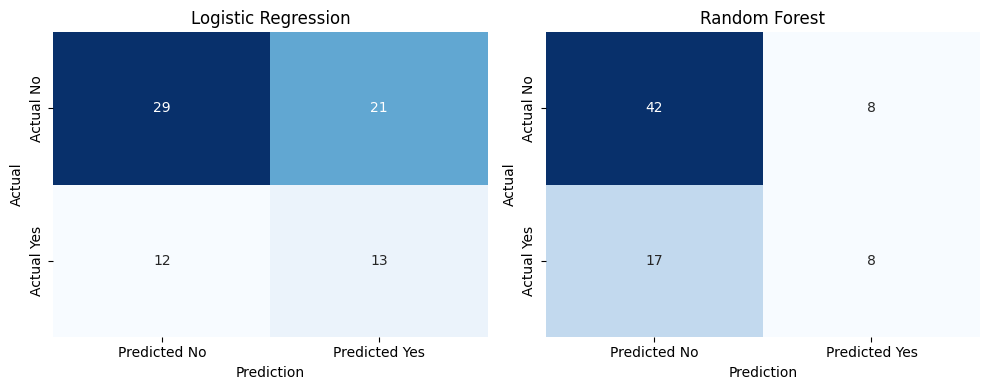

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))
for ax, name in zip(axes, models):
    cm = np.array(results[name]["confusion_matrix"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted No","Predicted Yes"],
                yticklabels=["Actual No","Actual Yes"])
    ax.set_title(name)
    ax.set_xlabel("Prediction")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 7. MLflow experiment tracking and model registry

This cell logs both models, their metrics and parameters. The model with the highest F1 score is registered as `WarpingDefectClassifier`. MLflow model registry support may vary by backend; the notebook uses a local SQLite-backed tracking store.

In [13]:
MLRUNS = str(PROJECT/"mlruns")
mlflow.set_tracking_uri("sqlite:///" + str(PROJECT/"mlflow.db"))
mlflow.set_experiment("FDM_Warping_Prediction")

# Define the trusted types needed by skops to deserialize the scikit-learn pipeline and tree structures
trusted_types = [
    "numpy.dtype",
    "sklearn.compose._column_transformer._RemainderColsList",
    "sklearn.tree._tree.Tree"
]

for name, pipe in fitted.items():
    with mlflow.start_run(run_name=name):
        mlflow.log_param("model", name)
        mlflow.log_param("dataset_version", "v1")
        mlflow.log_param("training_rows", len(X_train))
        for metric_name in ["precision","recall","f1","accuracy"]:
            mlflow.log_metric(metric_name, results[name][metric_name])
        mlflow.sklearn.log_model(pipe, artifact_path="model", skops_trusted_types=trusted_types)

# Register selected model from a fresh MLflow run
with mlflow.start_run(run_name=f"Register_{best_name}") as run:
    mlflow.log_param("selected_model", best_name)
    mlflow.log_param("selection_rule", "highest test F1")
    mlflow.log_metric("precision", results[best_name]["precision"])
    mlflow.log_metric("recall", results[best_name]["recall"])
    mlflow.log_metric("f1", results[best_name]["f1"])
    mlflow.sklearn.log_model(
        best_model, artifact_path="model",
        registered_model_name="WarpingDefectClassifier",
        skops_trusted_types=trusted_types
    )
print("Registered model name: WarpingDefectClassifier")
print("MLflow tracking URI:", mlflow.get_tracking_uri())

2026/11/18 08:50:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/18 08:50:28 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/18 08:50:35 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Registered model name: WarpingDefectClassifier
MLflow tracking URI: sqlite:////content/warping_mlops/mlflow.db


Successfully registered model 'WarpingDefectClassifier'.
Created version '1' of model 'WarpingDefectClassifier'.


## 8. Save model bundle and demonstrate feature-store reuse

The complete sklearn pipeline (feature preprocessing + estimator) is serialized. The `predict_one` function accepts raw printer parameters, recreates the engineered features, and predicts risk.

In [14]:
MODEL_PATH = ARTIFACTS/"warping_model.joblib"
joblib.dump({"model":best_model, "model_name":best_name}, MODEL_PATH)

def prepare_input(raw_df):
    validate_raw(raw_df.assign(warping_defect="No") if "warping_defect" not in raw_df.columns
                 else raw_df)
    return engineer_features(raw_df)[NUMERIC + CATEGORICAL]

def predict_dataframe(raw_df):
    model_input = prepare_input(raw_df)
    probability = best_model.predict_proba(model_input)[:,1]
    prediction = best_model.predict(model_input)
    return pd.DataFrame({
        "warping_probability": probability,
        "prediction": np.where(prediction==1, "Warping Risk", "Print Conditions Acceptable")
    })

# Reuse the persisted feature store rather than recalculating features for training preview
reused_feature_store = pd.read_csv(DATA/"feature_store_v1.csv")
print("Reused feature-store rows:", len(reused_feature_store))
display(predict_dataframe(v1.drop(columns=["warping_defect"]).head()))

Reused feature-store rows: 300


,warping_probability,prediction
0,0.671321,Warping Risk
1,0.427448,Print Conditions Acceptable
2,0.497856,Print Conditions Acceptable
3,0.615360,Warping Risk
4,0.386473,Print Conditions Acceptable


## 9. Write FastAPI application (`/health` and `/predict`)

Run this service in Colab using a background Uvicorn process and test it through HTTP. The response includes the predicted category and probability.

In [15]:
app_code = r"""
from pathlib import Path
import joblib
import pandas as pd
import numpy as np
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

BASE = Path(__file__).resolve().parents[1]
bundle = joblib.load(BASE / "artifacts" / "warping_model.joblib")
model = bundle["model"]
app = FastAPI(title="FDM Warping Defect Prediction API", version="1.0")

class PrintJob(BaseModel):
    filament_material: str
    nozzle_temperature_c: float = Field(ge=170, le=300)
    bed_temperature_c: float = Field(ge=20, le=130)
    printing_speed_mm_s: float = Field(ge=5, le=200)
    ambient_temperature_c: float = Field(ge=-5, le=60)
    cooling_fan_speed_pct: float = Field(ge=0, le=100)
    component_base_area_mm2: float = Field(ge=10, le=20000)
    layer_height_mm: float = Field(ge=0.05, le=0.5)

def engineer(df):
    df = df.copy()
    df["nozzle_bed_temperature_difference"] = df["nozzle_temperature_c"] - df["bed_temperature_c"]
    factor = df["filament_material"].map({"PLA":0.8,"ABS":1.35,"PETG":1.0})
    df["cooling_stress_index"] = (
        (df["nozzle_bed_temperature_difference"].clip(lower=0)/100)
        * (1 + df["cooling_fan_speed_pct"]/100)
        * (1 + np.maximum(0,25-df["ambient_temperature_c"])/25)
        * factor
    )
    return df[[
        "nozzle_temperature_c","bed_temperature_c","printing_speed_mm_s",
        "ambient_temperature_c","cooling_fan_speed_pct","component_base_area_mm2",
        "layer_height_mm","nozzle_bed_temperature_difference","cooling_stress_index",
        "filament_material"
    ]]

@app.get("/health")
def health():
    return {"status":"healthy", "model":bundle["model_name"]}

@app.post("/predict")
def predict(job: PrintJob):
    if job.filament_material not in ["PLA","ABS","PETG"]:
        raise HTTPException(status_code=422, detail="filament_material must be PLA, ABS or PETG")
    raw = pd.DataFrame([job.model_dump()])
    x = engineer(raw)
    prob = float(model.predict_proba(x)[0,1])
    label = "Warping Risk" if int(model.predict(x)[0]) == 1 else "Print Conditions Acceptable"
    return {"prediction":label, "warping_probability":round(prob,4)}
"""
(SRC/"api.py").write_text(app_code)
print("Wrote", SRC/"api.py")

Wrote /content/warping_mlops/src/api.py


### Start the API and test both endpoints inside Colab

In [16]:
import time, requests, subprocess, os, signal
api_log = open(PROJECT/"api.log","w")
api_process = subprocess.Popen(
    [sys.executable, "-m", "uvicorn", "src.api:app", "--host", "127.0.0.1", "--port", "8000"],
    cwd=str(PROJECT), stdout=api_log, stderr=subprocess.STDOUT
)
time.sleep(3)
health_response = requests.get("http://127.0.0.1:8000/health", timeout=10)
print("Health:", health_response.status_code, health_response.json())

sample_job = {
    "filament_material":"ABS",
    "nozzle_temperature_c":245,
    "bed_temperature_c":75,
    "printing_speed_mm_s":85,
    "ambient_temperature_c":18,
    "cooling_fan_speed_pct":55,
    "component_base_area_mm2":3200,
    "layer_height_mm":0.24
}
prediction_response = requests.post("http://127.0.0.1:8000/predict", json=sample_job, timeout=10)
print("Prediction:", prediction_response.status_code, prediction_response.json())

Health: 200 {'status': 'healthy', 'model': 'Logistic Regression'}
Prediction: 200 {'prediction': 'Warping Risk', 'warping_probability': 0.6209}


## 10. Automated tests and GitHub Actions CI

The test suite checks valid parameter acceptance, invalid parameter rejection, API health and prediction response format. GitHub Actions installs dependencies and runs pytest on every push and pull request.

In [11]:
requirements = """
fastapi
uvicorn
pandas
numpy
scikit-learn
joblib
pydantic
pytest
httpx
mlflow
"""
(PROJECT/"requirements.txt").write_text(textwrap.dedent(requirements).strip()+"\n")

test_code = r"""
import sys
from pathlib import Path
sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from fastapi.testclient import TestClient
from src.api import app

client = TestClient(app)

def valid_job():
    return {
        "filament_material":"PLA",
        "nozzle_temperature_c":205,
        "bed_temperature_c":60,
        "printing_speed_mm_s":50,
        "ambient_temperature_c":24,
        "cooling_fan_speed_pct":65,
        "component_base_area_mm2":1200,
        "layer_height_mm":0.20
    }

def test_health():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json()["status"] == "healthy"

def test_prediction():
    response = client.post("/predict", json=valid_job())
    assert response.status_code == 200
    body = response.json()
    assert body["prediction"] in ["Warping Risk", "Print Conditions Acceptable"]
    assert 0 <= body["warping_probability"] <= 1

def test_invalid_temperature_rejected():
    job = valid_job()
    job["bed_temperature_c"] = 500
    response = client.post("/predict", json=job)
    assert response.status_code == 422

def test_invalid_material_rejected():
    job = valid_job()
    job["filament_material"] = "NYLON"
    response = client.post("/predict", json=job)
    assert response.status_code == 422
"""
(TESTS/"test_api.py").write_text(test_code)

workflow = """
name: FDM Warping MLOps CI
on:
  push:
  pull_request:
jobs:
  validate-and-test:
    runs-on: ubuntu-latest
    steps:
      - name: Checkout repository
        uses: actions/checkout@v4
      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt
      - name: Validate data and run API tests
        run: |
          python -c "import pandas as pd; d=pd.read_csv('data/printing_jobs_v1.csv'); assert len(d)>=250; assert set(d.filament_material)<=set(['PLA','ABS','PETG'])"
          pytest -q
"""
(PROJECT/".github/workflows").mkdir(parents=True, exist_ok=True)
(PROJECT/".github/workflows/ci.yml").write_text(textwrap.dedent(workflow).strip()+"\n")
print("Created requirements.txt, tests/test_api.py and .github/workflows/ci.yml")

Created requirements.txt, tests/test_api.py and .github/workflows/ci.yml


In [17]:
# Run tests locally in this Colab runtime with the python path explicitly configured
test_result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", str(TESTS)],
    env={**os.environ, "PYTHONPATH": str(PROJECT)},
    cwd=str(PROJECT), capture_output=True, text=True
)
print(test_result.stdout)
if test_result.returncode != 0:
    print(test_result.stderr)
    raise RuntimeError("Tests failed")

....                                                                     [100%]
4 passed in 1.96s



## 11. Workflow diagram

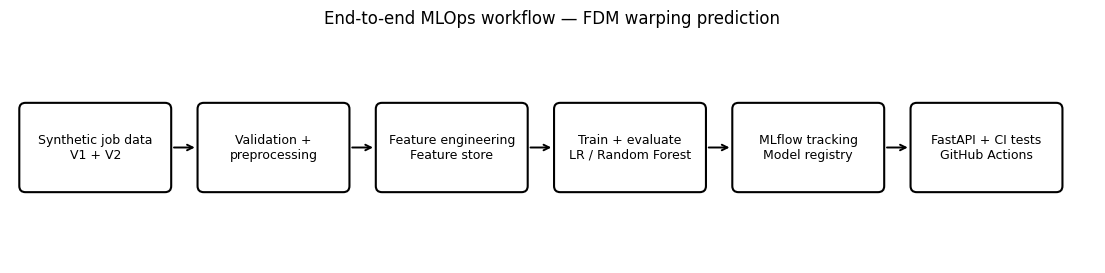

In [18]:
from IPython.display import Image, display
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14,3))
ax.set_xlim(0,14); ax.set_ylim(0,3); ax.axis("off")
steps = [
    ("Synthetic job data\nV1 + V2",0.2),
    ("Validation +\npreprocessing",2.5),
    ("Feature engineering\nFeature store",4.8),
    ("Train + evaluate\nLR / Random Forest",7.1),
    ("MLflow tracking\nModel registry",9.4),
    ("FastAPI + CI tests\nGitHub Actions",11.7)
]
for label,x in steps:
    patch=FancyBboxPatch((x,1),1.8,1.0,boxstyle="round,pad=0.08",fill=False,linewidth=1.5)
    ax.add_patch(patch); ax.text(x+0.9,1.5,label,ha="center",va="center",fontsize=9)
for i in range(len(steps)-1):
    ax.annotate("",xy=(steps[i+1][1]-0.08,1.5),xytext=(steps[i][1]+1.88,1.5),
                arrowprops=dict(arrowstyle="->",lw=1.4))
plt.title("End-to-end MLOps workflow — FDM warping prediction")
plt.show()

## 12. Generate PDF implementation report

This creates a concise PDF report with workflow, version comparison, metrics, confusion matrices and API response. Add your own screenshots from Colab / MLflow / GitHub after you run the notebook if your instructor requires actual UI screenshots.

In [22]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as RLImage
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import inch

pdf_path = PROJECT/"Warping_MLOps_Implementation_Report.pdf"
styles = getSampleStyleSheet()
story = [
    Paragraph("MLOps Experiment 7: Predicting Warping Defects in FDM 3D Printing", styles["Title"]),
    Spacer(1,12),
    Paragraph("Objective: predict whether a 3D-printed component is likely to develop a warping defect before printing begins.", styles["BodyText"]),
    Spacer(1,8),
    Paragraph("Dataset and versions", styles["Heading2"]),
    Paragraph(f"Version 1 contains {len(v1)} synthetic jobs. Version 2 contains {len(v2)} jobs with deliberately increased print speeds and reduced bed temperatures. V1 defect rate: {(v1.warping_defect=='Yes').mean():.1%}; V2 defect rate: {(v2.warping_defect=='Yes').mean():.1%}.", styles["BodyText"]),
    Spacer(1,8),
    Paragraph("Version comparison", styles["Heading3"]),
]
table_data = [["Parameter","V1 mean","V2 mean","Change"]]
for idx,row in comparison.iterrows():
    table_data.append([idx, f"{row['Version 1 mean']:.2f}", f"{row['Version 2 mean']:.2f}", f"{row['Change (V2 - V1)']:.2f}"])
t=Table(table_data, hAlign="LEFT")
t.setStyle(TableStyle([("BACKGROUND",(0,0),(-1,0),colors.lightgrey),("GRID",(0,0),(-1,-1),0.5,colors.grey),("PADDING",(0,0),(-1,-1),5)]))
story += [t, Spacer(1,10), Paragraph("Feature engineering and pipeline", styles["Heading2"]),
          Paragraph("Missing numerical values are median-imputed; categorical values are most-frequent-imputed and one-hot encoded; numerical features are standardized. Engineered features are nozzle_bed_temperature_difference and cooling_stress_index. Engineered features are persisted in the feature store CSV files and reused.", styles["BodyText"]),
          Spacer(1,8), Paragraph("Model comparison", styles["Heading2"])]
metric_data=[["Model","Precision","Recall","F1","Accuracy"]]
for name,row in metrics.iterrows():
    metric_data.append([name,*[f"{row[c]:.3f}" for c in ["precision","recall","f1","accuracy"]]])
mt=Table(metric_data,hAlign="LEFT")
mt.setStyle(TableStyle([("BACKGROUND",(0,0),(-1,0),colors.lightgrey),("GRID",(0,0),(-1,-1),0.5,colors.grey),("PADDING",(0,0),(-1,-1),5)]))
story += [mt, Spacer(1,8),
          Paragraph(f"Selected model: {best_name}, chosen using the highest test-set F1 score. The model was logged and registered in MLflow under the name WarpingDefectClassifier.", styles["BodyText"]),
          Spacer(1,8), Paragraph("Serving and CI/CD", styles["Heading2"]),
          Paragraph("FastAPI exposes GET /health and POST /predict. The prediction response includes either Warping Risk or Print Conditions Acceptable and a warping probability. GitHub Actions validates the dataset and runs automated pytest checks on pushes and pull requests.", styles["BodyText"]),
          Spacer(1,8), Paragraph("Example API prediction", styles["Heading2"]),
          Paragraph(f"HTTP status: {prediction_response.status_code}; response: {prediction_response.text}", styles["Code"]),
          Spacer(1,8), Paragraph("Limitations", styles["Heading2"]),
          Paragraph("All records and labels are synthetic and generated from illustrative rules. Before real deployment, collect validated printer telemetry and defect labels, perform external validation, calibrate probabilities, monitor drift and retrain under controlled change management.", styles["BodyText"])]
doc=SimpleDocTemplate(str(pdf_path),pagesize=A4,rightMargin=42,leftMargin=42,topMargin=42,bottomMargin=42)
doc.build(story)
print("PDF report created:", pdf_path)

PDF report created: /content/warping_mlops/Warping_MLOps_Implementation_Report.pdf


## 13. Download / export the complete project

The project directory contains datasets, feature-store files, model artifact, API, tests, CI workflow, requirements and PDF report. Zip it for GitHub upload.

In [24]:
# Stop the local API server
try:
    api_process.terminate()
except Exception:
    pass

zip_path = shutil.make_archive("/content/Warping_MLOps_Project", "zip", root_dir=str(PROJECT))
print("Project ZIP:", zip_path)
print("Files:")
for path in sorted(PROJECT.rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT))

Project ZIP: /content/Warping_MLOps_Project.zip
Files:
.github/workflows/ci.yml
.pytest_cache/.gitignore
.pytest_cache/CACHEDIR.TAG
.pytest_cache/README.md
.pytest_cache/v/cache/lastfailed
.pytest_cache/v/cache/nodeids
Warping_MLOps_Implementation_Report.pdf
api.log
artifacts/warping_model.joblib
data/feature_store_v1.csv
data/feature_store_v1.parquet
data/feature_store_v2.csv
data/feature_store_v2.parquet
data/printing_jobs_v1.csv
data/printing_jobs_v2.csv
mlflow.db
requirements.txt
src/__pycache__/api.cpython-313.pyc
src/api.py
tests/__pycache__/test_api.cpython-313-pytest-8.4.2.pyc
tests/test_api.py


In [25]:
from google.colab import files
import os

pdf_to_download = "/content/warping_mlops/Warping_MLOps_Implementation_Report.pdf"
zip_to_download = "/content/Warping_MLOps_Project.zip"

# Download the compiled PDF report
if os.path.exists(pdf_to_download):
    print("Downloading PDF implementation report...")
    files.download(pdf_to_download)
else:
    print(f"Error: {pdf_to_download} not found.")

# Download the complete project ZIP archive
if os.path.exists(zip_to_download):
    print("Downloading project ZIP archive...")
    files.download(zip_to_download)
else:
    print(f"Error: {zip_to_download} not found.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Push the project to GitHub

1. Download `Warping_MLOps_Project.zip` from the Colab Files panel.
2. Extract it on your computer.
3. Create a new GitHub repository, for example `fdm-warping-mlops`.
4. Upload the extracted project files (including the hidden `.github` folder).
5. Open **Actions** and confirm the workflow `FDM Warping MLOps CI` passes.
6. Copy the repository URL into your lab submission.

Do not commit secrets, API keys or personal access tokens. The MLflow local database and generated model artifact are included for this lab demonstration; for a team/production setup, use a managed tracking server and artifact store.